# Phân tích khám phá SOH
Dữ liệu chuyển đổi công khai dẫn nguồn NASA; chưa đối chiếu MAT gốc. Notebook chỉ mô tả dữ liệu và kết quả, không fit mô hình trên test.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
assert (ROOT / 'reports/features.csv').exists()
data = pd.read_csv(ROOT / 'reports/features.csv')
audit = pd.read_csv(ROOT / 'reports/data_audit.csv')
audit

,battery,rows,cycles,missing_values,min_soh_pct,max_soh_pct,zero_capacity_cycles,primary
0,B05,50285,168,0,64.372626,92.824371,0,True
1,B07,50285,168,0,70.022762,94.552615,0,True
2,B18,34866,132,0,67.052572,92.750226,0,True
3,B33,47065,197,0,3.421286,94.257008,0,False
4,B34,47065,197,0,37.296515,91.015300,0,False
5,B46,24519,72,0,0.000000,86.411962,3,False
6,B47,24519,72,0,0.000000,83.715237,3,False
7,B48,24519,72,0,0.000000,82.899779,3,False


## Thống kê từng pin
Nhãn SOH tính theo 2 Ah; 468 chu kỳ chính, không loại chu kỳ. Các pin bổ sung cần xác minh trước khi phân tích chung.

In [2]:
data.groupby('battery').agg(cycles=('cycle', 'count'), min_soh=('soh_pct', 'min'), max_soh=('soh_pct', 'max'))

,cycles,min_soh,max_soh
battery,,,
B05,168,64.372626,92.824371
B07,168,70.022762,94.552615
B18,132,67.052572,92.750226


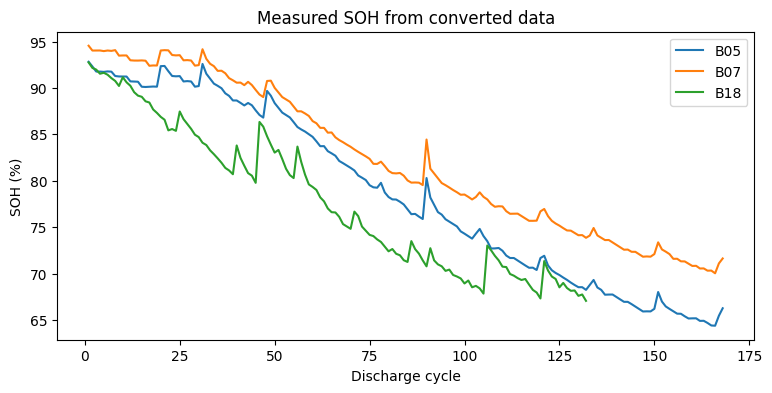

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
for battery, group in data.groupby('battery'):
    ax.plot(group.cycle, group.soh_pct, label=battery)
ax.set(xlabel='Discharge cycle', ylabel='SOH (%)', title='Measured SOH from converted data')
ax.legend()
plt.show()

## Tương quan mô tả
Tương quan trên dữ liệu gộp không chứng minh quan hệ nhân quả hoặc giá trị dự đoán trên pin mới. Không dùng biểu đồ này để chọn đặc trưng dựa trên test.

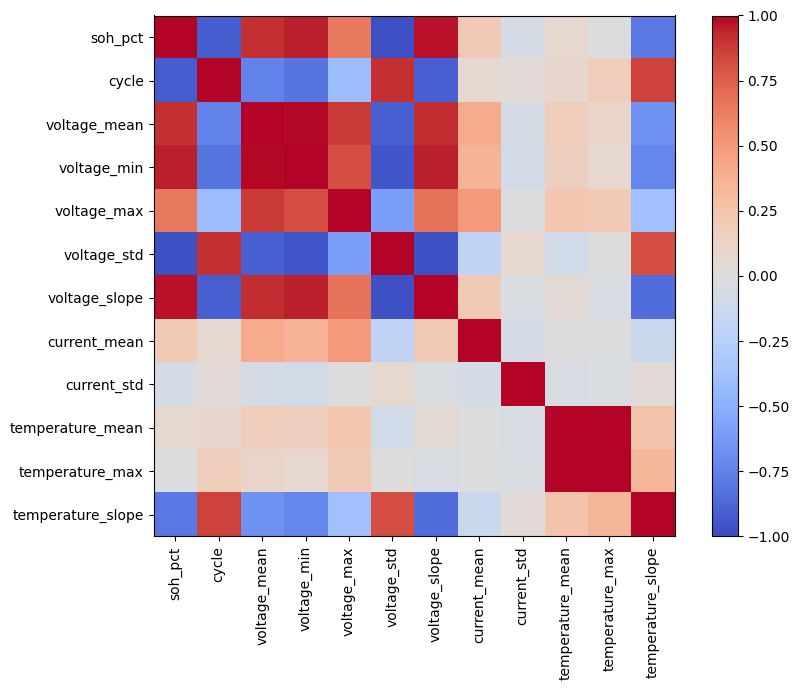

In [4]:
corr = data.drop(columns='battery').corr()
fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr)), corr.columns)
fig.colorbar(image, ax=ax)
fig.tight_layout()
plt.show()

## Kết quả leave-one-battery-out
MAE/RMSE đo bằng điểm phần trăm SOH; trung bình không trọng số giữa pin. Chỉ ba pin, chưa đủ kết luận về xe điện thực tế.

In [5]:
pd.read_csv(ROOT / 'reports/metrics_summary.csv')

,model,mae,rmse,r2
0,Mean baseline,7.728555,8.897808,-0.126248
1,Cycle Ridge,4.391850,4.676104,0.609407
2,Signal Ridge,5.300266,5.508338,0.492400
3,Random Forest,1.240919,1.627537,0.961536
4,HistGradientBoosting,1.250216,1.585669,0.961831


In [6]:
pd.read_csv(ROOT / 'reports/metrics_by_battery.csv')

,model,held_out_battery,n_train,n_test,mae,rmse,r2
0,Mean baseline,B05,300,168,8.668581,9.641200,-0.031627
1,Cycle Ridge,B05,300,168,2.053301,2.329825,0.939757
2,Signal Ridge,B05,300,168,3.706844,3.998414,0.822566
3,Random Forest,B05,300,168,1.255119,1.609956,0.971233
4,HistGradientBoosting,B05,300,168,1.047254,1.373464,0.979064
5,Mean baseline,B07,300,168,7.349478,8.930619,-0.238888
6,Cycle Ridge,B07,300,168,5.382487,5.615295,0.510205
7,Signal Ridge,B07,300,168,7.984780,8.070506,-0.011744
8,Random Forest,B07,300,168,1.264308,1.625790,0.958942
9,HistGradientBoosting,B07,300,168,1.224189,1.568004,0.961809


## Điểm cần xác minh
B05/B07 trong bản chuyển đổi có cùng trục thời gian. Checksum xác nhận phiên bản file, không xác nhận đúng với NASA gốc. Cần tái trích xuất dữ liệu gốc trước khi chốt kết luận khoa học.